# Resolución de un TSP restringido mediante QUBO y Simulated Annealing

En esta actividad se estudia un problema de optimización inspirado en el problema del viajante de comercio, TSP.

El objetivo es encontrar una ruta de coste mínimo que:

- parte de la ciudad 0,
- termina en la ciudad 0,
- visita una sola vez cada ciudad,
- respeta una restricción adicional sobre la posición de la ciudad 2.

El problema se modela como un problema QUBO, formato compatible con algoritmos de annealing como los utilizados en D-Wave.

Dado que no se dispone de acceso activo a los solvers de D-Wave, la resolución se realiza mediante Simulated Annealing, que es una técnica clásica inspirada en el proceso físico de enfriamiento y relacionada conceptualmente con Quantum Annealing.

# Librerias

In [2]:
#from google.colab import drive
#drive.mount('/content/drive')

import itertools
import random
import math

import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

## 1. Definición del grafo

El problema contiene cinco ciudades:

$V = \{0,1,2,3,4\}$

La ciudad $0$ representa el origen.

Del enunciado se extraen las siguientes distancias:

$d_{01}=3,\quad d_{03}=4,\quad d_{04}=2$

$d_{12}=3,\quad d_{13}=4$

$d_{23}=1,\quad d_{24}=6$

Además, el enunciado indica que no se proporciona la distancia entre el nodo $0$ y el nodo $2$. Por tanto, se asigna un valor razonable:

$d_{02}=4$

Este valor mantiene la escala de las demás distancias y no favorece excesivamente la conexión directa entre $0$ y $2$.

In [3]:
nodes = [0, 1, 2, 3, 4]
origin = 0

# Distancia elegida para la arista no especificada en el enunciado
d02 = 4

dist = {
    (0, 1): 3,
    (0, 2): d02,
    (0, 3): 4,
    (0, 4): 2,
    (1, 2): 3,
    (1, 3): 4,
    (2, 3): 1,
    (2, 4): 6,
}

# Grafo no dirigido: añadimos las distancias simétricas
for (i, j), value in list(dist.items()):
    dist[(j, i)] = value

# Penalización para aristas inexistentes
BIG_M = 100

def edge_exists(i, j):
    return (i, j) in dist

def cost(i, j):
    """
    Devuelve el coste de viajar de i a j.
    Si la arista no existe, se devuelve una penalización grande.
    """
    if i == j:
        return BIG_M
    return dist.get((i, j), BIG_M)

## 2. Visualización del grafo

Representamos el grafo para verificar las conexiones disponibles.

Las aristas que no existen no se dibujan. En el modelo de optimización, esas transiciones se penalizan mediante un valor grande \(M\).

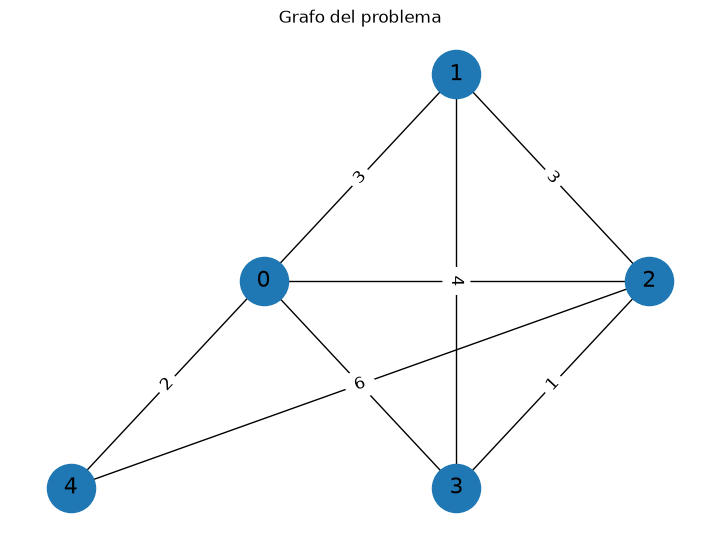

In [4]:
G = nx.Graph()

for node in nodes:
    G.add_node(node)

for (i, j), w in dist.items():
    if i < j:
        G.add_edge(i, j, weight=w)

pos = {
    0: (0, 0),
    1: (1, 1),
    2: (2, 0),
    3: (1, -1),
    4: (-1, -1),
}

plt.figure(figsize=(7, 5))
nx.draw(G, pos, with_labels=True, node_size=1200, font_size=16)
labels = nx.get_edge_attributes(G, "weight")
nx.draw_networkx_edge_labels(G, pos, edge_labels=labels, font_size=12)
plt.title("Grafo del problema")
plt.show()

## 3. Interpretación de la restricción sobre la ciudad 2

El enunciado indica que la ciudad $2$ debe ocupar una posición concreta en la ruta. Esta frase puede interpretarse de dos formas.

### Interpretación A

Se cuenta la ciudad $0$ como la primera ciudad visitada. Entonces, la segunda ciudad debe ser la ciudad $2$:

$0 \rightarrow 2 \rightarrow \cdots \rightarrow 0$

En este caso, imponemos que la ciudad $2$ aparezca en la posición $1$ de la ruta.

### Interpretación B

No se cuenta el origen como ciudad visitada. Entonces, la ciudad $2$ debe ser la segunda ciudad visitada después de salir del origen:

$0 \rightarrow x \rightarrow 2 \rightarrow \cdots \rightarrow 0$

En este caso, imponemos que la ciudad $2$ aparezca en la posición $2$ de la ruta.

A continuación se resolverán ambas interpretaciones.

In [5]:
def route_cost(route):
    """
    Calcula el coste total de una ruta.
    """
    return sum(cost(route[i], route[i + 1]) for i in range(len(route) - 1))


def is_valid_route(route, interpretation):
    """
    Comprueba si una ruta cumple las restricciones del problema.
    """

    # La ruta debe empezar y terminar en el origen
    if route[0] != origin or route[-1] != origin:
        return False

    # La ruta debe visitar exactamente una vez las ciudades distintas del origen
    if sorted(route[1:-1]) != [1, 2, 3, 4]:
        return False

    # Interpretación A:
    # La segunda ciudad de la ruta, contando el origen, debe ser 2.
    if interpretation == "A":
        return route[1] == 2

    # Interpretación B:
    # La segunda ciudad visitada sin contar el origen debe ser 2.
    if interpretation == "B":
        return route[2] == 2

    return False

## 4. Generación de rutas candidatas

Como hay cuatro ciudades distintas del origen, existen $4! = 24$ permutaciones posibles antes de aplicar restricciones.

Para cada interpretación, generamos las rutas que cumplen la restricción correspondiente y calculamos su coste.

Las aristas inexistentes reciben una penalización grande $M=100$, por lo que el modelo evita usarlas salvo que no haya alternativa.

In [6]:
def generate_candidate_routes(interpretation):
    """
    Genera todas las rutas candidatas para una interpretación dada.
    """
    candidates = []

    for perm in itertools.permutations([1, 2, 3, 4]):
        route = [origin] + list(perm) + [origin]

        if is_valid_route(route, interpretation):
            candidates.append({
                "route": route,
                "cost": route_cost(route),
                "uses_invalid_edges": any(
                    not edge_exists(route[i], route[i + 1])
                    for i in range(len(route) - 1)
                )
            })

    return candidates


for interp in ["A", "B"]:
    print(f"\nInterpretación {interp}")
    candidates = generate_candidate_routes(interp)

    for candidate in candidates:
        print(
            candidate["route"],
            "coste =", candidate["cost"],
            "usa aristas inexistentes =", candidate["uses_invalid_edges"]
        )


Interpretación A
[0, 2, 1, 3, 4, 0] coste = 113 usa aristas inexistentes = True
[0, 2, 1, 4, 3, 0] coste = 211 usa aristas inexistentes = True
[0, 2, 3, 1, 4, 0] coste = 111 usa aristas inexistentes = True
[0, 2, 3, 4, 1, 0] coste = 208 usa aristas inexistentes = True
[0, 2, 4, 1, 3, 0] coste = 118 usa aristas inexistentes = True
[0, 2, 4, 3, 1, 0] coste = 117 usa aristas inexistentes = True

Interpretación B
[0, 1, 2, 3, 4, 0] coste = 109 usa aristas inexistentes = True
[0, 1, 2, 4, 3, 0] coste = 116 usa aristas inexistentes = True
[0, 3, 2, 1, 4, 0] coste = 110 usa aristas inexistentes = True
[0, 3, 2, 4, 1, 0] coste = 114 usa aristas inexistentes = True
[0, 4, 2, 1, 3, 0] coste = 19 usa aristas inexistentes = False
[0, 4, 2, 3, 1, 0] coste = 16 usa aristas inexistentes = False


## 5. Solución óptima de referencia

Antes de construir el QUBO, calculamos la mejor ruta dentro de cada interpretación.

Esta solución se utilizará como referencia para comprobar si el algoritmo de optimización encuentra una ruta razonable.

En particular, se distingue entre:

- rutas que usan únicamente aristas existentes,
- rutas que requieren al menos una arista inexistente y, por tanto, reciben penalización $M$.

In [7]:
def best_candidate(interpretation, allow_invalid_edges=True):
    candidates = generate_candidate_routes(interpretation)

    if not allow_invalid_edges:
        candidates = [
            candidate for candidate in candidates
            if not candidate["uses_invalid_edges"]
        ]

    if len(candidates) == 0:
        return None

    return min(candidates, key=lambda c: c["cost"])


for interp in ["A", "B"]:
    print(f"\nInterpretación {interp}")

    best_with_penalty = best_candidate(interp, allow_invalid_edges=True)
    best_strict = best_candidate(interp, allow_invalid_edges=False)

    print("Mejor ruta permitiendo penalizaciones:")
    print(best_with_penalty)

    print("Mejor ruta usando solo aristas existentes:")
    print(best_strict)


Interpretación A
Mejor ruta permitiendo penalizaciones:
{'route': [0, 2, 3, 1, 4, 0], 'cost': 111, 'uses_invalid_edges': True}
Mejor ruta usando solo aristas existentes:
None

Interpretación B
Mejor ruta permitiendo penalizaciones:
{'route': [0, 4, 2, 3, 1, 0], 'cost': 16, 'uses_invalid_edges': False}
Mejor ruta usando solo aristas existentes:
{'route': [0, 4, 2, 3, 1, 0], 'cost': 16, 'uses_invalid_edges': False}


## 6. Formulación QUBO reducida

Para aplicar Simulated Annealing, construimos un modelo QUBO reducido.

En lugar de usar variables $x_{i,t}$ para indicar si la ciudad $i$ está en la posición $t$, usamos una variable binaria por cada ruta candidata:

$y_k =
\begin{cases}
1, & \text{si se selecciona la ruta candidata } k \\
0, & \text{en caso contrario}
\end{cases}$

El objetivo es seleccionar exactamente una ruta y minimizar su coste.

La energía del QUBO se define como:

$E(y)=\sum_k c_k y_k + A\left(1-\sum_k y_k\right)^2$

donde:

- $c_k$ es el coste de la ruta candidata $k$,
- $A$ es un parámetro de penalización,
- el término $A(1-\sum_k y_k)^2$ penaliza seleccionar cero rutas o más de una ruta.

Este modelo es un QUBO porque la función objetivo es cuadrática en variables binarias.

In [8]:
def qubo_energy(state, candidates, penalty=100):
    """
    Calcula la energía QUBO de un estado binario.

    state[k] = 1 significa que se selecciona la ruta candidata k.
    """
    costs = np.array([candidate["cost"] for candidate in candidates])
    y = np.array(state)

    route_cost_term = np.dot(costs, y)
    constraint_penalty = penalty * (1 - np.sum(y))**2

    return route_cost_term + constraint_penalty

## 7. Ejemplo de energía QUBO

Probamos la función de energía con la interpretación B.

Si se selecciona exactamente una ruta, la penalización es cero y la energía coincide con el coste de esa ruta.

Si se seleccionan cero rutas o varias rutas, aparece una penalización.

In [9]:
candidates_B = generate_candidate_routes("B")

print("Rutas candidatas para la interpretación B:")

for k, candidate in enumerate(candidates_B):
    print(k, candidate)

print("\nEjemplo seleccionando la primera ruta:")
state = [1] + [0] * (len(candidates_B) - 1)
print("Estado:", state)
print("Energía:", qubo_energy(state, candidates_B, penalty=100))

print("\nEjemplo seleccionando ninguna ruta:")
state = [0] * len(candidates_B)
print("Estado:", state)
print("Energía:", qubo_energy(state, candidates_B, penalty=100))

print("\nEjemplo seleccionando dos rutas:")
state = [1, 1] + [0] * (len(candidates_B) - 2)
print("Estado:", state)
print("Energía:", qubo_energy(state, candidates_B, penalty=100))

Rutas candidatas para la interpretación B:
0 {'route': [0, 1, 2, 3, 4, 0], 'cost': 109, 'uses_invalid_edges': True}
1 {'route': [0, 1, 2, 4, 3, 0], 'cost': 116, 'uses_invalid_edges': True}
2 {'route': [0, 3, 2, 1, 4, 0], 'cost': 110, 'uses_invalid_edges': True}
3 {'route': [0, 3, 2, 4, 1, 0], 'cost': 114, 'uses_invalid_edges': True}
4 {'route': [0, 4, 2, 1, 3, 0], 'cost': 19, 'uses_invalid_edges': False}
5 {'route': [0, 4, 2, 3, 1, 0], 'cost': 16, 'uses_invalid_edges': False}

Ejemplo seleccionando la primera ruta:
Estado: [1, 0, 0, 0, 0, 0]
Energía: 109

Ejemplo seleccionando ninguna ruta:
Estado: [0, 0, 0, 0, 0, 0]
Energía: 100

Ejemplo seleccionando dos rutas:
Estado: [1, 1, 0, 0, 0, 0]
Energía: 325


## 8. Resolución mediante Simulated Annealing

Una vez definido el QUBO, lo resolvemos mediante Simulated Annealing.

Simulated Annealing es un algoritmo clásico inspirado en el proceso físico de enfriamiento. Parte de una solución inicial y propone cambios aleatorios. Si el cambio mejora la energía, se acepta. Si empeora, puede aceptarse con una probabilidad que depende de la temperatura.

La probabilidad de aceptar un cambio peor es:

$P = e^{-\Delta E/T}$

donde:

- $\Delta E$ es el aumento de energía,
- $T$ es la temperatura actual.

Al inicio, $T$ es alta y el algoritmo explora más. Al final, $T$ disminuye y el algoritmo se vuelve más selectivo.

In [10]:
def random_state(n):
    """
    Genera un estado binario aleatorio de longitud n.
    """
    return [random.randint(0, 1) for _ in range(n)]


def neighbor_state(state):
    """
    Genera un vecino cambiando un bit aleatorio.
    """
    new_state = state.copy()
    index = random.randint(0, len(state) - 1)
    new_state[index] = 1 - new_state[index]
    return new_state

In [11]:
def simulated_annealing(
    candidates,
    penalty=100,
    max_iter=5000,
    initial_temperature=50,
    cooling_rate=0.995,
    seed=42
):
    """
    Resuelve el QUBO reducido mediante Simulated Annealing.
    """
    random.seed(seed)

    n = len(candidates)

    current_state = random_state(n)
    current_energy = qubo_energy(current_state, candidates, penalty)

    best_state = current_state.copy()
    best_energy = current_energy

    temperature = initial_temperature

    history = []

    for iteration in range(max_iter):
        candidate_state = neighbor_state(current_state)
        candidate_energy = qubo_energy(candidate_state, candidates, penalty)

        delta = candidate_energy - current_energy

        if delta < 0:
            accept = True
        else:
            accept_probability = math.exp(-delta / temperature) if temperature > 0 else 0
            accept = random.random() < accept_probability

        if accept:
            current_state = candidate_state
            current_energy = candidate_energy

        if current_energy < best_energy:
            best_state = current_state.copy()
            best_energy = current_energy

        history.append(current_energy)
        temperature *= cooling_rate

    return best_state, best_energy, history

## 9. Ejecución del algoritmo

Ejecutamos Simulated Annealing para ambas interpretaciones.

Después de obtener el estado binario óptimo, decodificamos qué ruta ha sido seleccionada.

In [12]:
def decode_selected_route(state, candidates):
    """
    Convierte un estado binario en la ruta seleccionada.
    """
    selected_indices = [i for i, bit in enumerate(state) if bit == 1]

    if len(selected_indices) != 1:
        return None

    return candidates[selected_indices[0]]


sa_results = {}

for interp in ["A", "B"]:
    print(f"\nInterpretación {interp}")

    candidates = generate_candidate_routes(interp)

    best_state, best_energy, history = simulated_annealing(
        candidates,
        penalty=100,
        max_iter=5000,
        initial_temperature=50,
        cooling_rate=0.995,
        seed=42
    )

    selected_route = decode_selected_route(best_state, candidates)

    sa_results[interp] = {
        "state": best_state,
        "energy": best_energy,
        "history": history,
        "selected_route": selected_route
    }

    print("Mejor estado binario:", best_state)
    print("Mejor energía:", best_energy)
    print("Ruta seleccionada:", selected_route)


Interpretación A
Mejor estado binario: [0, 0, 0, 0, 0, 0]
Mejor energía: 100
Ruta seleccionada: None

Interpretación B
Mejor estado binario: [0, 0, 0, 0, 0, 1]
Mejor energía: 16
Ruta seleccionada: {'route': [0, 4, 2, 3, 1, 0], 'cost': 16, 'uses_invalid_edges': False}


## 10. Análisis de resultados

Los resultados obtenidos permiten comparar ambas interpretaciones del enunciado.

### Interpretación A

No existe ninguna ruta que utilice únicamente aristas existentes del grafo.

El algoritmo selecciona el estado nulo, lo que implica que es preferible pagar la penalización antes que elegir una ruta inválida.

Esto indica que la interpretación A no es factible en términos del grafo proporcionado.

### Interpretación B

Se obtiene una solución válida:

$[0,4,2,3,1,0]$

con coste:

$16$

Esta ruta utiliza únicamente aristas existentes y coincide con la solución óptima obtenida mediante enumeración.

### Conclusión

La interpretación correcta del enunciado es la interpretación B, ya que es la única que produce soluciones factibles en el grafo dado.

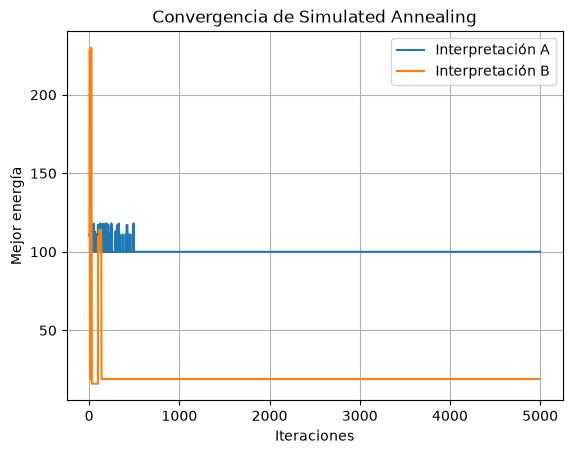

In [13]:
for interp in ["A", "B"]:
    history = sa_results[interp]["history"]

    plt.plot(history, label=f"Interpretación {interp}")

plt.xlabel("Iteraciones")
plt.ylabel("Mejor energía")
plt.title("Convergencia de Simulated Annealing")
plt.legend()
plt.grid()
plt.show()

## 11. Convergencia del algoritmo

La evolución de la energía muestra el comportamiento típico de Simulated Annealing.

En la interpretación B, la energía disminuye rápidamente hasta alcanzar el mínimo global, donde se estabiliza.

En la interpretación A, la energía permanece constante, indicando que no existen soluciones factibles que mejoren la penalización.

Este comportamiento es coherente con la estructura del problema y confirma la validez del modelo QUBO.



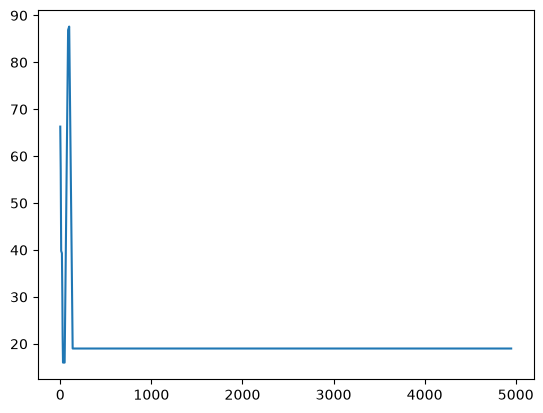

In [14]:
window = 50
smoothed = np.convolve(history, np.ones(window)/window, mode='valid')
plt.plot(smoothed)